<div align="center">

# **Fetal ECG Extraction by Blind Source Separation with Bio-Inspired Optimisation**

*How can bio-inspired optimisation algorithms be used to isolate the fetal cardiac activity<br>from abdominal recordings in which it is mixed with the maternal ECG?*

**Morgan SANTALUCIA** (*274326*) · **Owen LE DILY** (*XXXXXX*)

*Bio-Inspired Artificial Intelligence — Università degli Studi di Trento — 2026–2027, first semester*

</div>

---

In [52]:
# Imports and global settings

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import welch, butter, sosfiltfilt, sosfreqz
from sklearn.decomposition import FastICA

seed = 42  # random seed, for reproducible results

---

In [53]:
# Data loading

# All data are in the csv/ folder:
# - rXX.csv: one file per record (XX = patient number), sampled at fs.
#   Columns: t_s, Direct_1 (direct fetal scalp electrode), Abdomen_1 ... Abdomen_4
# - qrs.csv: reference fetal QRS annotations of all records.
#   Columns: record, sample, t_s
# - channels.csv: metadata of each channel.
#   Columns: record, channel, unit, fs, sensor_type, prefiltering,
#            physical_min, physical_max, digital_min, digital_max
data_dir = Path("csv")

signals = {f.stem: pd.read_csv(f) for f in sorted(data_dir.glob("r*.csv"))}
qrs = pd.read_csv(data_dir / "qrs.csv")
channels = pd.read_csv(data_dir / "channels.csv")

# Same sampling frequency (1 kHz) for every channel of every record
fs = channels["fs"].iloc[0]

---

In [54]:
# Observation matrix of the first record

abdominal_channels = ["Abdomen_1", "Abdomen_2", "Abdomen_3", "Abdomen_4"]

# Observation matrix X (mixing model X = H S): one row per abdominal channel,
# one column per sample -> shape (4, N), with N = 300 000 (5 min at 1 kHz) for every record
X01 = signals["r01"][abdominal_channels].to_numpy().T
print(X01.shape)

display(
    pd.DataFrame(
        X01[:, :6],
        index=[f"x{i + 1} = {c}" for i, c in enumerate(abdominal_channels)],
        columns=[f"n = {k}" for k in range(6)],
    ).round(2)
)

(4, 300000)


,n = 0,n = 1,n = 2,n = 3,n = 4,n = 5
x1 = Abdomen_1,-8.85,-13.95,-18.75,-23.45,-27.95,-32.85
x2 = Abdomen_2,13.35,12.65,12.05,11.45,10.45,8.65
x3 = Abdomen_3,22.05,21.75,21.25,20.25,18.55,15.95
x4 = Abdomen_4,32.55,35.35,37.55,38.95,39.45,39.25


### Blind source separation: the problem and its assumptions

Each abdominal electrode records a mixture of several signals: the mother's heart, the fetus's heart, and noise. 
We only have these mixtures; we do not know the original signals, nor how they were mixed. 
Blind source separation (BSS) aims to recover the original signals from the mixtures alone ("blind" = without knowing the mixing).

**What BSS assumes about the recordings**

**1. Each electrode records a simple weighted sum of the sources.**

Every electrode sees the same signals at the same time, only with different strengths: an electrode close to the fetus picks up more fetal signal, one close to the mother's heart picks up more maternal signal.
*In our case:* the electrical activity of the hearts spreads through the body almost instantly, so there is no delay between electrodes. 

**2. The mixture does not change during the analysis.**

The weight of each source on each electrode must stay the same over the analysed segment.
*In our case:* the fetus moves and the mother breathes, which changes these weights over time. Which is why we analyse the record in 15 s windows.

**3. There are not more sources than electrodes.**

With 4 electrodes, we can recover at most 4 sources.
*In our case:* maternal heart, fetal heart and noise fit in 4 outputs. But the maternal signal is strong and may take up more than one output. 

**4. The sources differ in some measurable way.**

To separate signals without knowing them, they must differ by a property we can measure on the outputs. This property is the *separation criterion*; the separation becomes the search for the outputs that maximise it.
*In our case:* we use two properties of the heart signals.
- *They are unrelated:* the two hearts beat independently, each at its own pace (about 85 bpm for the mother, 130 bpm for the fetus in r01).
- *They do not look like random noise:* an ECG is flat most of the time, then a sharp peak at each beat. Mixing signals makes them look more like noise; separating them makes the peaks stand out again.


**What BSS cannot tell us.** 

The outputs come in an arbitrary order, with an arbitrary sign and amplitude. We get 4 signals, but not which one is the fetus: we have to identify it afterwards (for example from its heart rate).

### Mixing model

$$\mathbf{X} = \mathbf{H}\,\mathbf{S}$$

| Symbol | Meaning | Size |
|---|---|---|
| $\mathbf{X}$ | observations: the 4 abdominal channels | $m \times N$ ($m = 4$, $N$ samples) |
| $\mathbf{S}$ | unknown sources: maternal ECG, fetal ECG, noise | $n \times N$ |
| $\mathbf{H}$ | unknown mixing matrix: $h_{ij}$ = weight of source $j$ on electrode $i$ | $m \times n$ |

Goal: find a separating matrix $\mathbf{W}$ such that $\mathbf{Y} = \mathbf{W}\mathbf{X} \approx \mathbf{S}$.

---

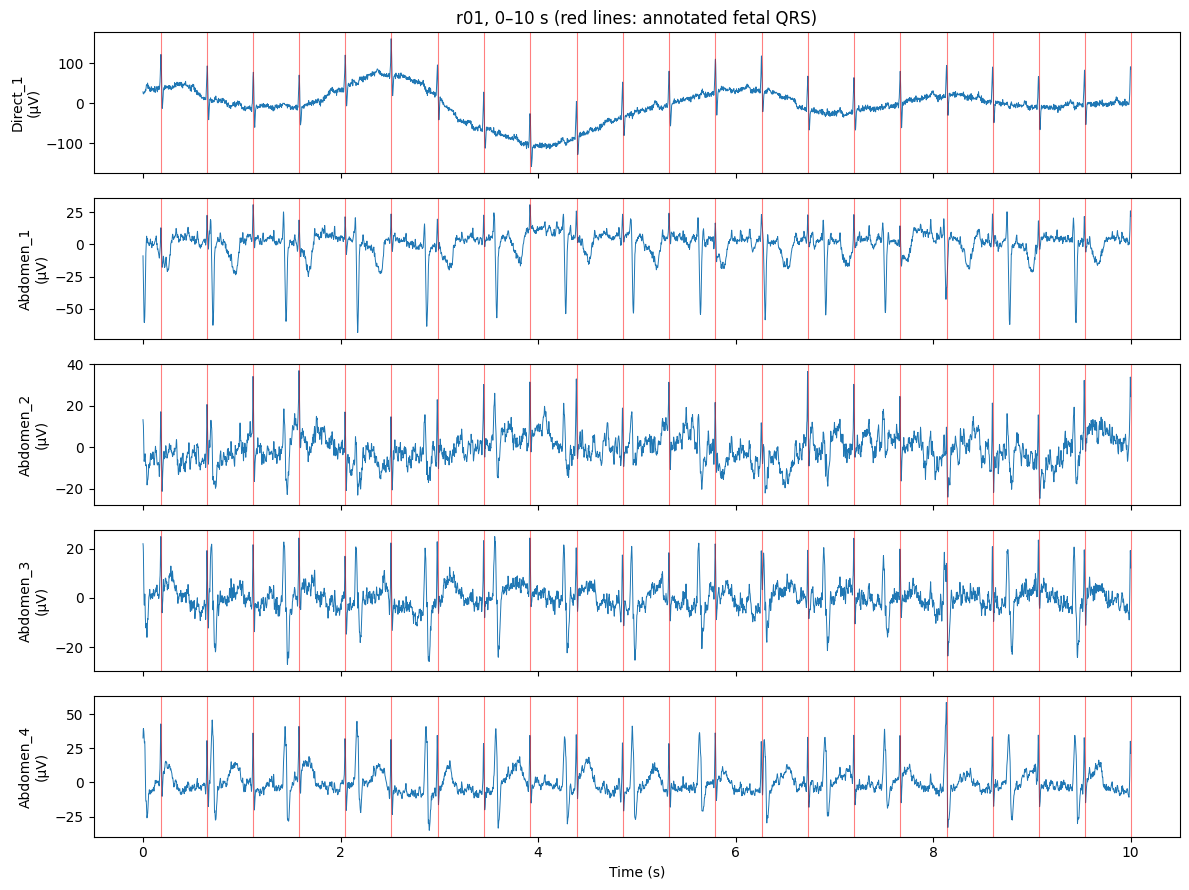

In [55]:
# Raw channels of one record, with the reference fetal QRS annotations

record, t_start, duration = "r01", 0, 10   # in seconds; change to look at another time window

df = signals[record]
window = df[(df["t_s"] >= t_start) & (df["t_s"] < t_start + duration)]
qrs_window = qrs[
    (qrs["record"] == record)
    & (qrs["t_s"] >= t_start)
    & (qrs["t_s"] < t_start + duration)
]

channel_names = list(df.columns[1:])   # Direct_1 + the 4 abdominal channels (t_s excluded)

fig, axes = plt.subplots(len(channel_names), 1, figsize=(12, 9), sharex=True)
for ax, ch in zip(axes, channel_names):
    ax.plot(window["t_s"], window[ch], linewidth=0.7)
    # Fetal QRS annotated by experts on Direct_1, drawn on every channel for comparison.
    ax.vlines(qrs_window["t_s"], 0, 1, transform=ax.get_xaxis_transform(),
              color="red", linewidth=0.8, alpha=0.5)
    ax.set_ylabel(f"{ch}\n(µV)")

axes[0].set_title(f"{record}, {t_start}–{t_start + duration} s (red lines: annotated fetal QRS)")
axes[-1].set_xlabel("Time (s)")
plt.tight_layout()
plt.show()

---

In [56]:
# Cut X01 into consecutive 15 s windows

window_duration = 15                       # s

n = int(window_duration * fs)              # samples per window (fs is a float)
n_windows = X01.shape[1] // n              # 300 s / 15 s = 20 windows
starts = [k * window_duration for k in range(n_windows)]

windows = {t0: X01[:, k * n : (k + 1) * n] for k, t0 in enumerate(starts)}   # {t0: 4 x n matrix}

# Annotated fetal QRS of each window, in seconds from the window start
qrs_r01 = qrs[qrs["record"] == "r01"]["t_s"].to_numpy()
qrs_windows = {t0: qrs_r01[(qrs_r01 >= t0) & (qrs_r01 < t0 + window_duration)] - t0 for t0 in starts}

print(f"{n_windows} windows of shape {windows[starts[0]].shape}")
for t0 in starts:
    print(f"{t0:3d}–{t0 + window_duration:3d} s: {len(qrs_windows[t0])} annotated QRS")

20 windows of shape (4, 15000)
  0– 15 s: 32 annotated QRS
 15– 30 s: 33 annotated QRS
 30– 45 s: 32 annotated QRS
 45– 60 s: 32 annotated QRS
 60– 75 s: 32 annotated QRS
 75– 90 s: 32 annotated QRS
 90–105 s: 31 annotated QRS
105–120 s: 32 annotated QRS
120–135 s: 32 annotated QRS
135–150 s: 32 annotated QRS
150–165 s: 33 annotated QRS
165–180 s: 32 annotated QRS
180–195 s: 35 annotated QRS
195–210 s: 34 annotated QRS
210–225 s: 33 annotated QRS
225–240 s: 31 annotated QRS
240–255 s: 32 annotated QRS
255–270 s: 31 annotated QRS
270–285 s: 31 annotated QRS
285–300 s: 32 annotated QRS


---

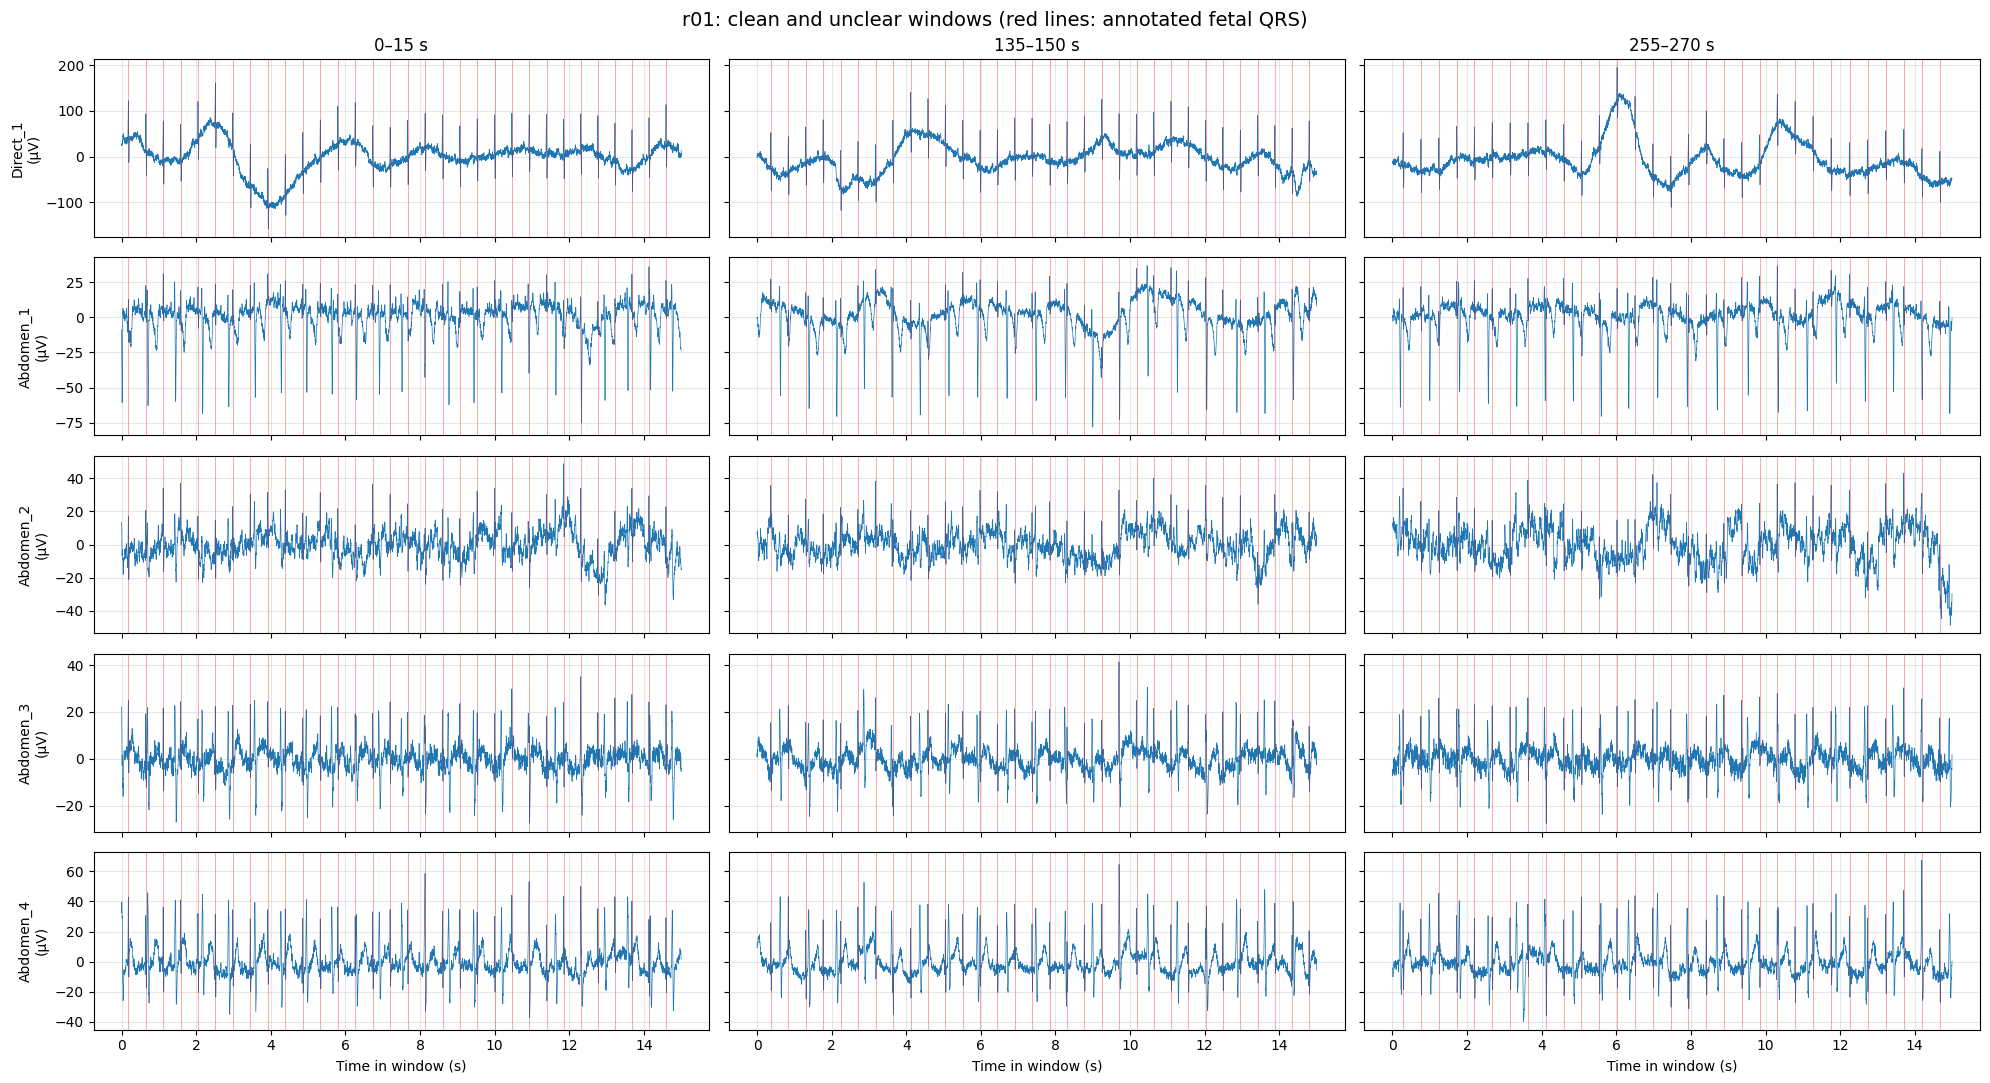

In [57]:
# Grid of windows: one column per window, one row per channel
# (Direct_1 as reference, then the 4 abdominal channels)

plot_starts = [0, 135, 255]   # choose the windows to display

direct = signals["r01"]["Direct_1"].to_numpy()
plot_channels = ["Direct_1"] + abdominal_channels
t = np.arange(n) / fs                                  # local time in each window, from 0 to 15 s

fig, axes = plt.subplots(len(plot_channels), len(plot_starts), figsize=(20, 11),
                         sharex=True, sharey="row", squeeze=False)

for j, t0 in enumerate(plot_starts):
    k0 = int(t0 * fs)
    window_signals = np.vstack([direct[k0 : k0 + n], windows[t0]])   # 5 x n

    for i, ch in enumerate(plot_channels):
        ax = axes[i, j]
        ax.plot(t, window_signals[i], linewidth=0.5, color="tab:blue")
        ax.vlines(qrs_windows[t0], 0, 1, transform=ax.get_xaxis_transform(),
                  color="red", linewidth=0.6, alpha=0.4)
        ax.grid(alpha=0.3)

        if i == 0:
             ax.set_title(f"{t0}–{t0 + window_duration} s")
        if j == 0:
            ax.set_ylabel(f"{ch}\n(µV)")
        if i == len(plot_channels) - 1:
            ax.set_xlabel("Time in window (s)")

fig.suptitle("r01: clean and unclear windows (red lines: annotated fetal QRS)", fontsize=14)
plt.tight_layout()
plt.show()

---

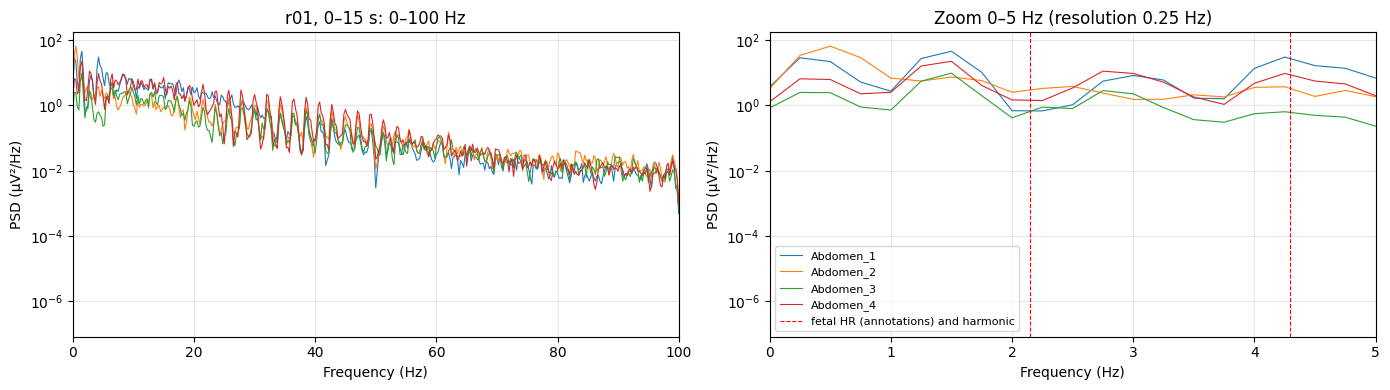

Fetal heart rate in this window: 2.15 Hz = 129 bpm


In [58]:
# Power spectral density (PSD) of one 15 s window, channel by channel

t0_psd = 0                          # start of the analysed window (a multiple of 15 s)
segment_duration = 4                # s, length of the Welch segments

x_win = windows[t0_psd]             # 4 x n
nperseg = int(segment_duration * fs)

# Fetal heart rate of this window, from the annotations: f_fetal = 1 / median RR interval
f_fetal = 1 / np.median(np.diff(qrs_windows[t0_psd]))

fig, (ax_full, ax_zoom) = plt.subplots(1, 2, figsize=(14, 4))

for i, ch in enumerate(abdominal_channels):
    f, psd = welch(x_win[i], fs=fs, nperseg=nperseg)
    ax_full.semilogy(f, psd, linewidth=0.8, label=ch)
    ax_zoom.semilogy(f, psd, linewidth=0.8, label=ch)

# Fetal fundamental and harmonics (a periodic heartbeat gives lines at k * f_fetal)
for k in range(1, 3):
    ax_zoom.axvline(k * f_fetal, color="red", linestyle="--", linewidth=0.8,
                    label="fetal HR (annotations) and harmonic" if k == 1 else None)

ax_full.set_xlim(0, 100)
ax_full.set_title(f"r01, {t0_psd}–{t0_psd + window_duration} s: 0–100 Hz")
ax_zoom.set_xlim(0, 5)
ax_zoom.set_title(f"Zoom 0–5 Hz (resolution {fs / nperseg:.2f} Hz)")
for ax in (ax_full, ax_zoom):
    ax.set_xlabel("Frequency (Hz)")
    ax.set_ylabel("PSD (µV²/Hz)")
    ax.grid(alpha=0.3)
ax_zoom.legend(fontsize=8)
plt.tight_layout()
plt.show()

print(f"Fetal heart rate in this window: {f_fetal:.2f} Hz = {60 * f_fetal:.0f} bpm")


The power spectral density (PSD) is estimated with Welch's method: the window is cut into 4 s segments overlapping by 50 %, the periodogram of each segment is computed, and the periodograms are averaged. 

Averaging reduces the variance of the estimate; the price is a frequency resolution of $\Delta f = f_s / N_{seg} = 0.25$ Hz instead of $1/15$ Hz for a single periodogram of the whole window.

- *Left (0–100 Hz):* most of the power lies between 5 and 40 Hz. This is the QRS complexes, short and steep, hence wide-band. It motivates the use of a band-pass filter.

- *Right (0–5 Hz):* a heartbeat is quasi-periodic, so its spectrum shows lines at the heart rate and its harmonics. The maternal line is near 1.5 Hz (≈ 85–90 bpm) with harmonics near 3 and 4.5 Hz; the fetal line is near 2.1 Hz (≈ 128 bpm, red dashed line from the annotations).

- The two hearts occupy overlapping frequency bands (harmonics of one fall near the lines of the other, and both QRS share the 5–40 Hz band). A simple filter cannot separate them, which is why we use the spatial diversity of the 4 electrodes (blind source separation) rather than the frequency content alone.

---

### Independent component analysis (ICA) on the filtered signals

ICA estimates sources from linear mixtures of statistically independent, non-Gaussian signals. 
Analogy: 3 instruments play at the same time and 3 microphones each record a different mixture; ICA recovers what each instrument played. Here the "instruments" are the maternal heart, the fetal heart and the noise, and the "microphones" are the 4 abdominal electrodes.

More details here :

- https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.FastICA.html

- https://scikit-learn.org/stable/auto_examples/decomposition/plot_ica_blind_source_separation.html



We filter firt the signals of the matrix.

- *High-pass at 5 Hz:* removes the baseline wander (breathing, electrode movement, below ~1 Hz) and the slow P and T waves. These slow components are strongly correlated between channels and dominated by the mother; they would take ICA components without helping to find the fetus.

- *Low-pass at 40 Hz:* removes high-frequency muscle noise (abdominal EMG) and the residual of the 50 Hz mains interference (the recordings are already pre-filtered at acquisition: low-pass 150 Hz, comb 50 Hz, see `channels.csv`).

- *What is kept:* the QRS complexes, short and steep, whose energy lies mostly between 5 and 40 Hz (see the PSD above). The fetal QRS is the only reliable fetal signature in abdominal recordings.



Filtering does not break the mixing model. 

The same linear time-invariant filter $h$ is applied to every channel, so it commutes with an instantaneous mixture:
$$h * \mathbf{X} = h * (\mathbf{H}\mathbf{S}) = \mathbf{H}\,(h * \mathbf{S}).$$
The mixing matrix $\mathbf{H}$ is unchanged and ICA simply works on filtered sources.



We design the filter based on our signal processing knowledge acquired in previous courses as signal processing students. 

- *Butterworth, order 4:* maximally flat passband, so the QRS shape is not distorted inside the band.

- *Second-order sections (`output="sos"`):* the filter is computed as a cascade of order-2 filters, numerically more stable than a single high-order polynomial.

- *Zero-phase filtering (`sosfiltfilt`):* the signal is filtered forward then backward. The phase shifts cancel, so the QRS stay aligned with the annotation times; the effective order doubles (magnitude response squared).

- *Whole record first, then windows:* filtering each 15 s window separately would create transients at every window edge.

In [59]:
# Band-pass filtering of the whole record, then windowing

f_low, f_high = 5, 40       # Hz, pass band
filter_order = 4

bandpass_filter = butter(filter_order, [f_low, f_high], btype="band", fs=fs, output="sos")
X01_f = sosfiltfilt(bandpass_filter, X01, axis=1)                    # filter each channel (row)
direct_f = sosfiltfilt(bandpass_filter, signals["r01"]["Direct_1"].to_numpy())

windows_filtered = {t0: X01_f[:, k * n : (k + 1) * n] for k, t0 in enumerate(starts)}

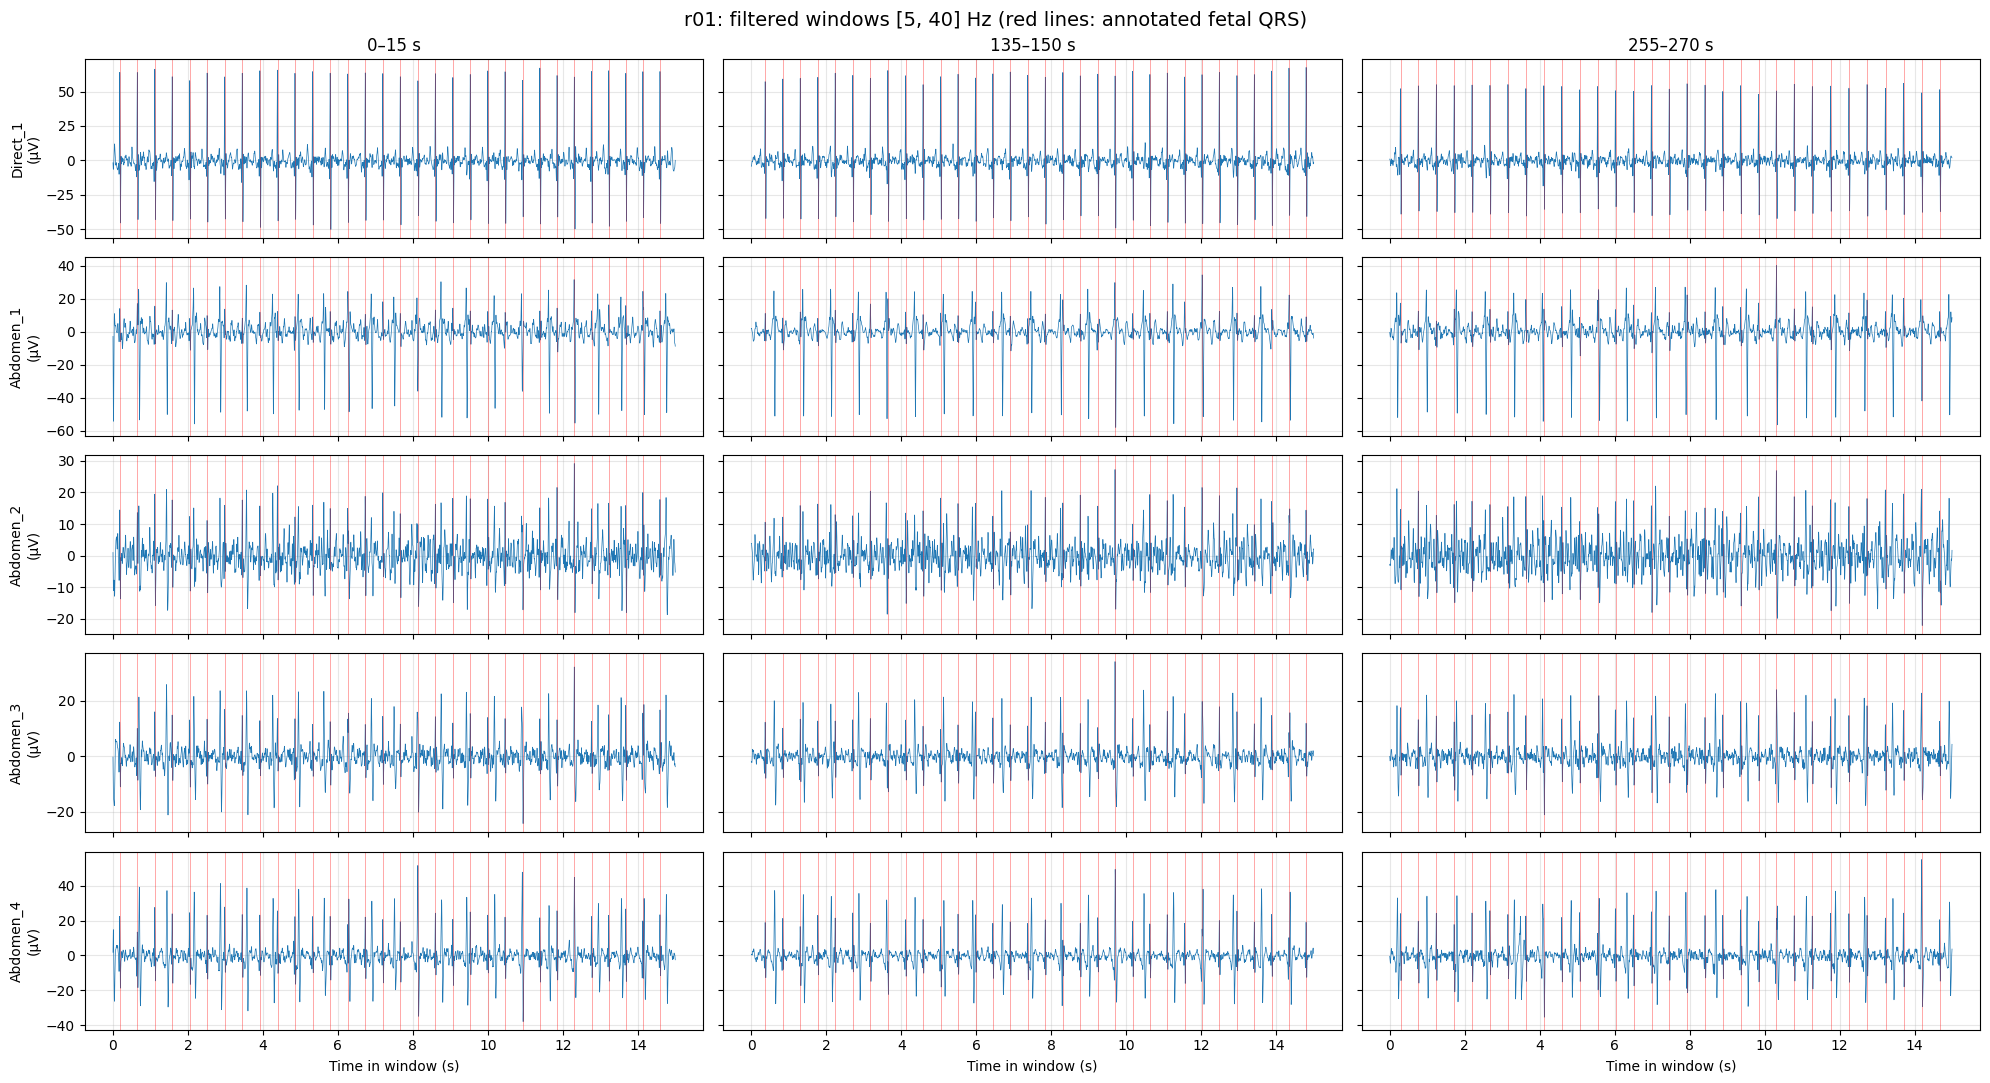

In [60]:
# Filtered windows: same grid and same windows as the raw grid, for comparison

fig, axes = plt.subplots(len(plot_channels), len(plot_starts), figsize=(20, 11),
                         sharex=True, sharey="row", squeeze=False)

for j, t0 in enumerate(plot_starts):
    k0 = int(t0 * fs)
    window_signals = np.vstack([direct_f[k0 : k0 + n], windows_filtered[t0]])   # 5 x n

    for i, ch in enumerate(plot_channels):
        ax = axes[i, j]
        ax.plot(t, window_signals[i], linewidth=0.5, color="tab:blue")
        ax.vlines(qrs_windows[t0], 0, 1, transform=ax.get_xaxis_transform(),
                  color="red", linewidth=0.6, alpha=0.4)
        ax.grid(alpha=0.3)

        if i == 0:
            ax.set_title(f"{t0}–{t0 + window_duration} s")
        if j == 0:
            ax.set_ylabel(f"{ch}\n(µV)")
        if i == len(plot_channels) - 1:
            ax.set_xlabel("Time in window (s)")

fig.suptitle(f"r01: filtered windows [{f_low}, {f_high}] Hz (red lines: annotated fetal QRS)", fontsize=14)
plt.tight_layout()
plt.show()

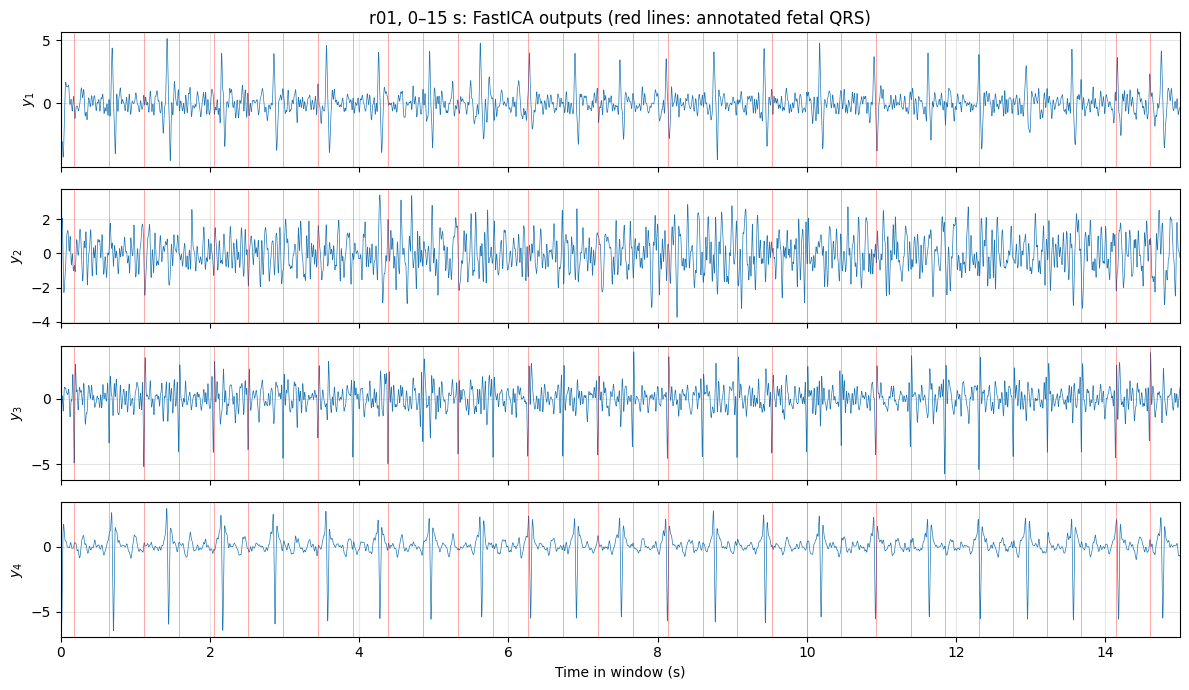

In [64]:
# FastICA on one filtered window

t0_ica = 0                             # start of the analysed window (a multiple of 15 s)
x_win_f = windows_filtered[t0_ica]           # 4 x n

ica = FastICA(n_components=4, whiten="unit-variance", max_iter=1000, random_state=seed)
Y = ica.fit_transform(x_win_f.T).T           # scikit-learn expects (samples, channels): transpose in and out -> 4 x n

fig, axes = plt.subplots(4, 1, figsize=(12, 7), sharex=True)
for i, ax in enumerate(axes):
    ax.plot(t, Y[i], linewidth=0.5)
    ax.vlines(qrs_windows[t0_ica], 0, 1, transform=ax.get_xaxis_transform(),
              color="red", linewidth=0.6, alpha=0.4)
    ax.set_ylabel(f"$y_{i + 1}$")
    ax.grid(alpha=0.3)
axes[0].set_title(f"r01, {t0_ica}–{t0_ica + window_duration} s: FastICA outputs (red lines: annotated fetal QRS)")
axes[-1].set_xlabel("Time in window (s)")
axes[-1].set_xlim(0, window_duration)
plt.tight_layout()
plt.show()

---

## ChangeLog : 

`fichier` → `data_dir`

`signaux` → `signals`

`abdomen` → `abdominal_channels`

`enregistrement` → `record`

`t_debut` → `t_start`

`t_final` → `duration` 

`duree` → `window_duration`

`fenetres` → `windows`

`qrs_fenetres` → `qrs_windows`


---